# Hypothesis-driven EDA for California Housing



> **Observe → form a hypothesis → choose a visualisation → read the evidence → note the caveats.**

### What you will learn

| Section | Topic |
|---------|-------|
| 1 | Loading a real dataset from a package and profiling it |
| 2 | The hypothesis-driven EDA loop |
| 3 | Worked hypothesis #1: income vs. house value |
| 4 | Worked hypothesis #2: location (a map from two columns) |
| 5 | Data-quality hooks: a hidden price cap and impossible outliers |

**Dataset — California Housing.** 20,640 California *neighbourhoods* (census "block
groups") from the 1990 US Census, bundled with scikit-learn.

| Column | Meaning |
|--------|---------|
| `MedInc` | Median household income in the block (in tens of thousands of $) |
| `MedHouseVal` | **Median house value (in $100,000s)** — what we want to explain |
| `HouseAge` | Median age of the houses (years) |
| `AveRooms` | Average rooms per household |
| `AveBedrms` | Average bedrooms per household |
| `Population` | People living in the block |
| `AveOccup` | Average household size (people per home) |
| `Latitude`, `Longitude` | Location of the block |
        

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 110

print("Setup complete.")

Setup complete.


In [2]:
from sklearn.datasets import fetch_openml

# Real data: 20,640 California neighbourhoods ("block groups") from the 1990 US Census.
# Loaded via OpenML (the original scikit-learn download URL is currently blocked).
raw = fetch_openml(name='california_housing', version=1, as_frame=True, parser='auto').frame

# Rename columns to match the original notebook's naming convention
homes = raw.rename(columns={
    'median_income': 'MedInc',
    'median_house_value': 'MedHouseVal',
    'housing_median_age': 'HouseAge',
    'longitude': 'Longitude',
    'latitude': 'Latitude',
    'population': 'Population',
})
# Derive average columns from totals (divide by households)
homes['AveRooms'] = raw['total_rooms'] / raw['households']
homes['AveBedrms'] = raw['total_bedrooms'] / raw['households']
homes['AveOccup'] = raw['population'] / raw['households']

# Reorder columns to match original
homes = homes[['MedInc', 'MedHouseVal', 'HouseAge', 'AveRooms', 'AveBedrms',
               'Population', 'AveOccup', 'Latitude', 'Longitude']]

print(f"Shape: {homes.shape}")
homes.head()

Shape: (20640, 9)


,MedInc,MedHouseVal,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,452600,41,6.984127,1.023810,322,2.555556,37.88,-122.23
1,8.3014,358500,21,6.238137,0.971880,2401,2.109842,37.86,-122.22
2,7.2574,352100,52,8.288136,1.073446,496,2.802260,37.85,-122.24
3,5.6431,341300,52,5.817352,1.073059,558,2.547945,37.85,-122.25
4,3.8462,342200,52,6.281853,1.081081,565,2.181467,37.85,-122.25


---
## Section 1 — Profile the Dataset

First pass: size, types, missing values, and numeric summary.
        

In [3]:
print("Shape:", homes.shape)
print("Missing values:", int(homes.isnull().sum().sum()))
homes.describe()
        

Shape: (20640, 9)
Missing values: 207


,MedInc,MedHouseVal,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,206855.816909,28.639486,5.429000,1.097062,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,115395.615874,12.585558,2.474173,0.476104,1132.462122,10.386050,2.135952,2.003532
min,0.499900,14999.000000,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,119600.000000,18.000000,4.440716,1.006029,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,179700.000000,29.000000,5.229129,1.048889,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,264725.000000,37.000000,6.052381,1.099631,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,500001.000000,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


---
## Section 2 — The Hypothesis-Driven EDA Loop

Beyond the first profile, good EDA is **question-driven**. For each idea you have, run this
loop:

1. **Observe** — something in the data or your background knowledge sparks a question.
2. **Hypothesis** — state it as a *specific, checkable* claim, e.g. *"richer neighbourhoods
   have more expensive houses."* (Not "income matters somehow.")
3. **Visualise** — pick the chart that would show it: scatter for two numerics, box plot
   across groups, a map for location, …
4. **Read the evidence** — does the picture *support*, *refute*, or *complicate* the claim?
   Back it with one number (a correlation or a group mean).
5. **Caveats** — what could mislead you here? Confounders, outliers, capped values?

Let's do two together, then you'll run the loop yourself.
        

---
## Section 3 — Worked Hypothesis #1: *Richer areas have pricier houses*

- **Hypothesis:** higher `MedInc` → higher `MedHouseVal`.
- **Visualise:** a scatter plot of the two.
        

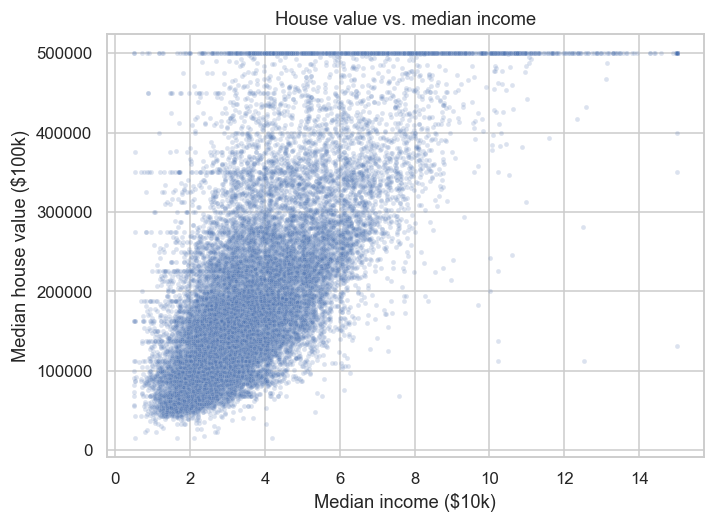

Correlation (MedInc, MedHouseVal): 0.688


In [4]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=homes, x="MedInc", y="MedHouseVal", alpha=0.2, s=10)
plt.title("House value vs. median income")
plt.xlabel("Median income ($10k)"); plt.ylabel("Median house value ($100k)")
plt.show()

print("Correlation (MedInc, MedHouseVal):", round(homes["MedInc"].corr(homes["MedHouseVal"]), 3))
        

**Read the evidence:** a clear upward trend and a strong correlation (~0.69) — the
hypothesis is **supported**; income is the single best predictor of value here.
**Caveat:** notice the flat line of dots along the very top — we'll explain that in
Section 5.
        

---
## Section 4 — Worked Hypothesis #2: *Location drives price*

- **Hypothesis:** where a neighbourhood *is* matters — coastal areas cost more.
- **Visualise:** plot every block at its `Longitude`/`Latitude` and **colour by value**.
        

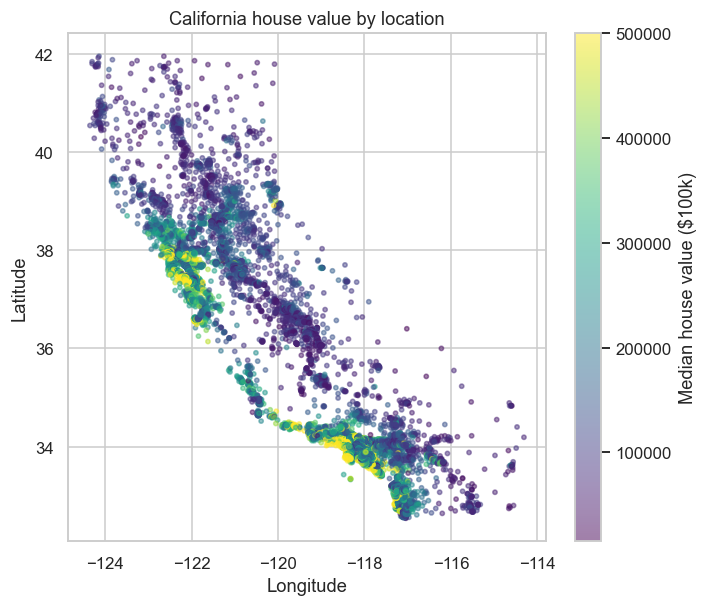

In [5]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(homes["Longitude"], homes["Latitude"],
                 c=homes["MedHouseVal"], cmap="viridis", s=8, alpha=0.5)
plt.colorbar(sc, label="Median house value ($100k)")
plt.title("California house value by location")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()
        

>  **Finding — two number columns just drew a map.**
> You didn't load a single shape or boundary, yet the outline of **California** appears —
> and it's not uniform: the bright (expensive) blocks hug the **coast**, the **Bay Area**,
> and **Los Angeles**, while the inland Central Valley stays dark. *Location is clearly a
> major driver of price* — and a plain scatter of two columns revealed it.
        

---
## Section 5 — Data-Quality Hooks

EDA isn't only about relationships — it's also where you catch problems the documentation
never mentions.

### Hook A — the hidden price cap
        

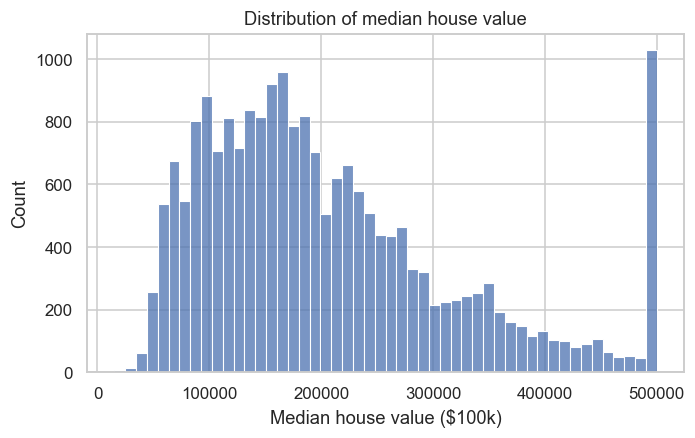

Maximum value: 500001 ($50000100k)
Neighbourhoods stuck exactly at that maximum: 965


In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(homes["MedHouseVal"], bins=50)
plt.title("Distribution of median house value")
plt.xlabel("Median house value ($100k)")
plt.show()

cap = homes["MedHouseVal"].max()
print("Maximum value:", cap, "($%.0fk)" % (cap * 100))
print("Neighbourhoods stuck exactly at that maximum:", int((homes["MedHouseVal"] == cap).sum()))
        

>  **Finding — the spike at the right edge.**
> There's an unnatural **tower of bars at ~5.0** ($500k). Nearly **1,000 neighbourhoods**
> report *exactly* the same maximum value — because the 1990 Census **capped** recorded
> house values at $500,000. Any block worth more was recorded as $500k. This is
> **censoring**: a real data-quality issue that would quietly cap your model's predictions
> if you didn't spot it.

### Hook B — impossible-looking outliers
        

Average rooms per household — max: 141.9
Average household size (AveOccup) — max: 1243.3


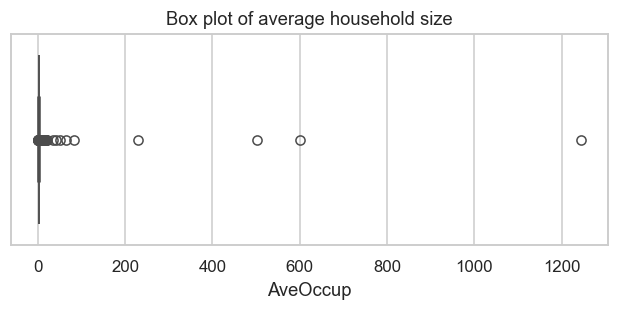

In [7]:
print("Average rooms per household — max:", round(homes["AveRooms"].max(), 1))
print("Average household size (AveOccup) — max:", round(homes["AveOccup"].max(), 1))

plt.figure(figsize=(7, 2.5))
sns.boxplot(x=homes["AveOccup"])
plt.title("Box plot of average household size")
plt.show()
        

A neighbourhood with **142 rooms per household** or **1,243 people per home**? Those can't
be literal. They come from tiny block groups with very few households (e.g. a holiday area
with lots of people but almost no permanent homes), which makes these *averages* explode.
Real data, real explanation — but you must **notice and question** such values before
trusting any analysis built on them.
        

---
## Key Takeaways

1. EDA is **question-driven**: *observe → hypothesise → visualise → read evidence → caveats.*
2. State hypotheses as **specific, checkable** claims, and back conclusions with a number.
3. Plotting **Latitude/Longitude coloured by a value** turns two columns into a **map**.
4. Histograms and box plots expose **data-quality hooks** — a value **cap** (censoring) and
   **impossible outliers** — that no summary statistic announces on its own.
        

---
## Exercises

Run the **hypothesis loop** for each. Aim for: a one-line hypothesis, a plot, a number, and
a one-sentence verdict.

1. **Spot the suspicious column.** For every numeric column compute `max / median`. Which
   column's maximum is most wildly inflated relative to its typical value, and how does that
   connect to Section 5? *(Hint: `homes.max() / homes.median()`.)*
2. **Hypothesis — older houses are cheaper.** Test `HouseAge` vs `MedHouseVal`: compute
   their correlation **and make a scatter plot**. Is the relationship strong, weak, or
   basically absent? State your verdict.
3. **Hypothesis — crowded areas differ in price.** Create a categorical column
   `crowded = homes["AveOccup"] > 3`, then **make a box plot** of `MedHouseVal` split by
   `crowded`, and compare the group medians. Does crowding relate to value?
4. **Re-draw the map for income.** Repeat the Section 4 location plot but colour by
   `MedInc` instead of value. In one sentence, how does the income map compare to the value
   map — and what does that similarity suggest?
5. **The cap, quantified.** What **percentage** of all neighbourhoods sit exactly at the
   $500k cap? *(Hint: count rows at the max, divide by `len(homes)`.)* Why would this
   percentage matter to someone training a price-prediction model?
6. **Challenge — your own investigation.** Form one hypothesis this notebook didn't test
   (e.g. about `AveBedrms`, `Population`, or combining columns), then run the full loop:
   hypothesis → plot → supporting number → verdict → one caveat that could undermine it.
        

---
## Exercise Solutions

### Exercise 1: Spot the suspicious column

In [8]:
# 计算每列的 max/median
max_over_median = homes.max() / homes.median()
print("Max / Median for each column:")
print(max_over_median.sort_values(ascending=False))

Max / Median for each column:
AveOccup       441.193154
AveBedrms       32.478814
Population      30.602058
AveRooms        27.138190
MedInc           4.243550
MedHouseVal      2.782421
HouseAge         1.793103
Latitude         1.224460
Longitude        0.964723
dtype: float64


### Exercise 2: Hypothesis — older houses are cheaper

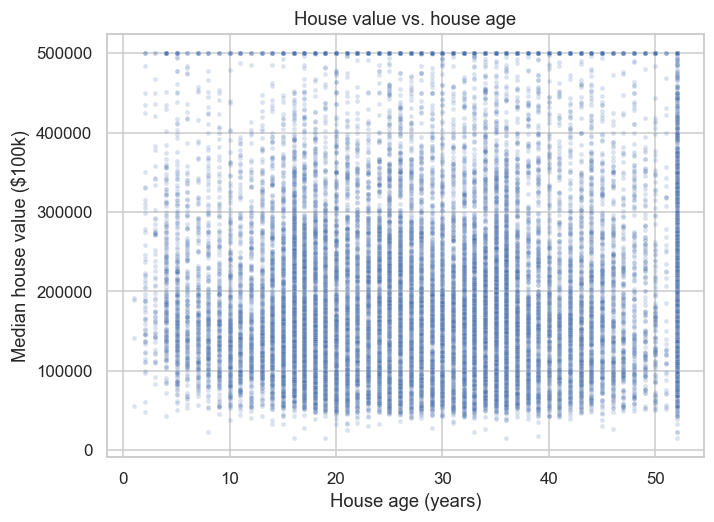

Correlation (HouseAge, MedHouseVal): 0.106


In [9]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=homes, x="HouseAge", y="MedHouseVal", alpha=0.2, s=10)
plt.title("House value vs. house age")
plt.xlabel("House age (years)"); plt.ylabel("Median house value ($100k)")
plt.show()

corr = homes["HouseAge"].corr(homes["MedHouseVal"])
print("Correlation (HouseAge, MedHouseVal):", round(corr, 3))

### Exercise 3: Hypothesis — crowded areas differ in price

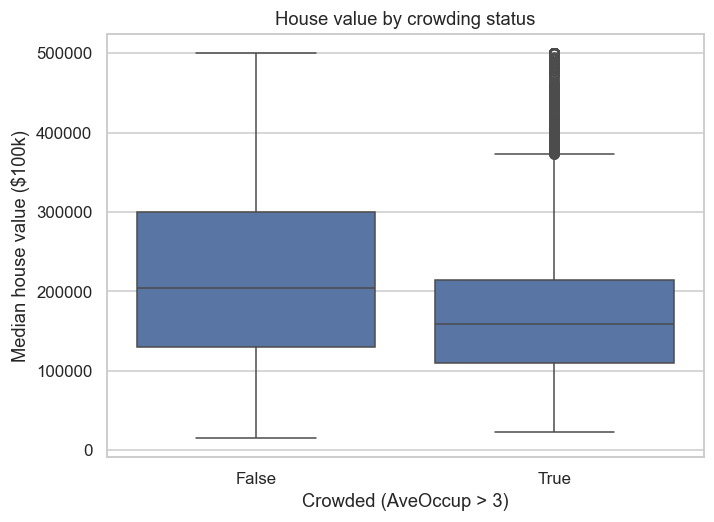

Median value, not crowded: 203700.00 ($100k)
Median value, crowded: 158500.00 ($100k)


In [10]:
# 创建拥挤列
homes["crowded"] = homes["AveOccup"] > 3

plt.figure(figsize=(7, 5))
sns.boxplot(data=homes, x="crowded", y="MedHouseVal")
plt.title("House value by crowding status")
plt.xlabel("Crowded (AveOccup > 3)"); plt.ylabel("Median house value ($100k)")
plt.show()

# 比较中位数
median_not_crowded = homes[~homes["crowded"]]["MedHouseVal"].median()
median_crowded = homes[homes["crowded"]]["MedHouseVal"].median()
print(f"Median value, not crowded: {median_not_crowded:.2f} ($100k)")
print(f"Median value, crowded: {median_crowded:.2f} ($100k)")

### Exercise 4: Re-draw the map for income

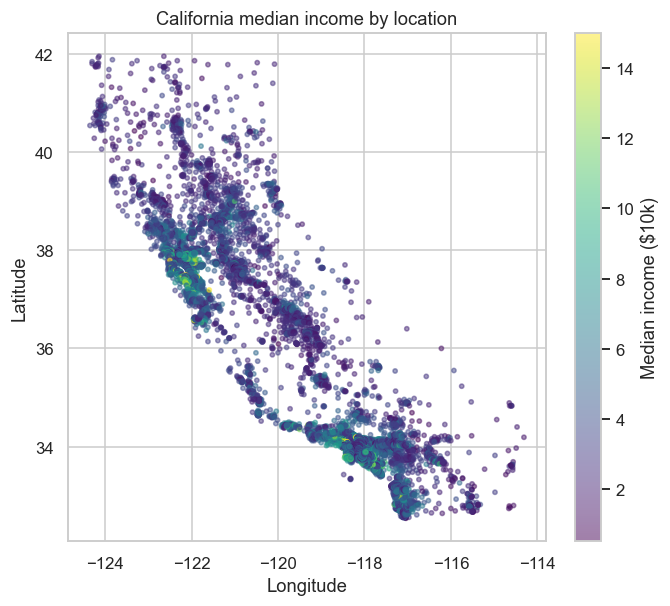

In [11]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(homes["Longitude"], homes["Latitude"],
                 c=homes["MedInc"], cmap="viridis", s=8, alpha=0.5)
plt.colorbar(sc, label="Median income ($10k)")
plt.title("California median income by location")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()

### Exercise 5: The cap, quantified

In [12]:
cap = homes["MedHouseVal"].max()
cap_count = (homes["MedHouseVal"] == cap).sum()
percentage = (cap_count / len(homes)) * 100
print(f"Percentage of neighbourhoods at $500k cap: {percentage:.2f}%")

Percentage of neighbourhoods at $500k cap: 4.68%


### Exercise 6: Challenge — your own investigation

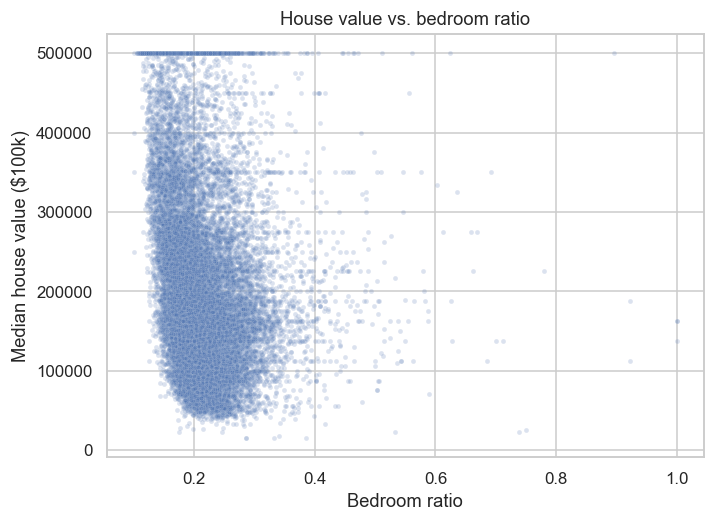

Correlation (bedroom_ratio, MedHouseVal): -0.256


In [13]:
# 假设：卧室比例高的区域房价更低
homes["bedroom_ratio"] = homes["AveBedrms"] / homes["AveRooms"]

plt.figure(figsize=(7, 5))
sns.scatterplot(data=homes, x="bedroom_ratio", y="MedHouseVal", alpha=0.2, s=10)
plt.title("House value vs. bedroom ratio")
plt.xlabel("Bedroom ratio"); plt.ylabel("Median house value ($100k)")
plt.show()

corr = homes["bedroom_ratio"].corr(homes["MedHouseVal"])
print("Correlation (bedroom_ratio, MedHouseVal):", round(corr, 3))